# Project 3. Part 1 - CLD Aggregation Tool

Last update: 05/23/2024

Title: Streamlining the Aggregation of Causal Loop Diagrams: A Thematic Labeling and Adjacency Matrix Approach

Overview: 
Spaghetti Causal Loop Diagrams (CLDs) present a significant challenge for modelers in effectively communicating complex system dynamics to stakeholders. Traditionally, modelers manually synthesize multiple CLDs to create an aggregated diagram that provides a higher-level understanding of the system. This paper introduces a streamlined procedure for aggregating CLDs using general categorical labels. 

The methodology involves translating qualitative mental models into adjacency matrices that capture both links and polarity signs, manually coding and substituting variable names with thematic labels, aggregating these matrices to identify significant feedback loops, and validating the approach by comparing it with the manual synthesis performed by an expert system dynamicist. 

Our results demonstrate that this tool is highly useful for group model-building experts, particularly when dealing with a large number of mental maps. The proposed method enhances the clarity and efficiency of synthesizing complex CLDs, thereby improving the overall communication of system dynamics.







In [1]:
%load_ext autoreload
%autoreload 2

In [3]:
import numpy as np
import os 
import pickle
import pandas as pd
import sys
import networkx as nx
import matplotlib.pyplot as plt
import gravis as gv

# Add the src directory to the sys.path
sys.path.append(os.path.abspath(os.path.join('..', 'src')))

import parse_cld
import cld_nx
import data_io


In [4]:
# Set the new directory
new_dir = "/Users/gl665/PycharmProjects/Phrame_MentalMaps"
# Change the current working directory
os.chdir(new_dir)

print(os.getcwd())

/Users/gl665/PycharmProjects/Phrame_MentalMaps


In [5]:
# Read all the json files in 
my_data_RC = {}
folder_path = 'results/SYNCH/JSON_file/RC/'

my_data_RC = data_io.read_json(folder_path, my_data_RC)

results/SYNCH/JSON_file/RC/FM 51220Clean.json
load: FM 51220Clean.json
results/SYNCH/JSON_file/RC/Passages Clean.json
load: Passages Clean.json
results/SYNCH/JSON_file/RC/full circle GBM 5 24 21clean.json
load: full circle GBM 5 24 21clean.json
results/SYNCH/JSON_file/RC/C 7 6 20 clean model.json
load: C 7 6 20 clean model.json
results/SYNCH/JSON_file/RC/tracy clean model.json
load: tracy clean model.json
results/SYNCH/JSON_file/RC/Wavi combined clean.json
load: Wavi combined clean.json
results/SYNCH/JSON_file/RC/drug justice model clean.json
load: drug justice model clean.json
results/SYNCH/JSON_file/RC/7 13 20 clean model.json
load: 7 13 20 clean model.json
results/SYNCH/JSON_file/RC/DSS23.json
load: DSS23.json
results/SYNCH/JSON_file/RC/E clean model 572020.json
load: E clean model 572020.json
results/SYNCH/JSON_file/RC/nat model clean2.json
load: nat model clean2.json
results/SYNCH/JSON_file/RC/j model 7 13 20 clean model3.json
load: j model 7 13 20 clean model3.json
results/SYNCH/

In [6]:
file_rename = pd.read_excel('results/SYNCH/file_rename/RC_file_rename.xlsx', index_col=0)
file_rename['file_no.'] = [i+1 for i in range(len(file_rename.index))]
file_rename.head(3)

,Filename,Model Name,file_no.
0,FM 51220Clean.json,FM,1
1,Passages Clean.json,PA,2
2,full circle GBM 5 24 21clean.json,FullGMB,3


In [23]:
# preprocess the RC_Updated_Themes.xslx and match it back with the RC files. 
# df_rc_themes = pd.read_excel('Dataset/SYNCH/aggregate_theme/RC_Updated_Themes.xlsx', sheet_name= "clean")

# # get column 1 and 4
# df_aggregate_names = df_rc_themes.iloc[:, [1, 4]]

# df_aggregate_names.columns = ['theme', 'variable']
# # delete rows if both are column values are nan 
# df_aggregate_names = df_aggregate_names.dropna(subset=['theme', 'variable'], how='all')


# df_aggregate_names['theme'] = df_aggregate_names['theme'].fillna(method='ffill')
# df_aggregate_names['theme']= df_aggregate_names['theme'].str.lower()
# df_aggregate_names['variable']= df_aggregate_names['variable'].str.lower()

# df_aggregate_names.head(20)
# df_aggregate_names.to_csv('Dataset/SYNCH/aggregate_theme/RC_theme_var_matching.csv', index=False)

In [13]:
df_aggregate_names = pd.read_csv('data/SYNCH/aggregate_theme/RC_theme_var_matching.csv')
unique_theme_names = set(df_aggregate_names['theme'])
df_aggregate_names.head()


,theme,variable
0,healthy development,child psychological development
1,healthy development,healthy child development
2,healthy development,child behavioral issues
3,healthy development,child physcial violent perpetration
4,healthy development,developmental delay in child


In [9]:
dict_pol_mx = {}
for key, value in my_data_RC.items():
    print(key)
    merge_df,  theme_dict = parse_cld.get_theme_cld(value, df_aggregate_names)
    adj_mx = parse_cld.get_aggregate_adjacency_mx(merge_df,  theme_dict)
    pol_mx = parse_cld.get_aggregate_polarity_mx (merge_df, theme_dict)
    # print(pol_mx.shape)
    dict_pol_mx[key] = pol_mx 


FM 51220Clean.json
Passages Clean.json
full circle GBM 5 24 21clean.json
C 7 6 20 clean model.json
tracy clean model.json
Wavi combined clean.json
drug justice model clean.json
7 13 20 clean model.json
DSS23.json
E clean model 572020.json
nat model clean2.json
j model 7 13 20 clean model3.json
FC Prov Clean.json
full circle clean.json
reentry clean model.json
1 6 21 Legal clean.json
DV justice model clean.json
SOC clean.json
RC 4 28 2021 Clean.json


In [28]:
# df_theme_dict = pd.DataFrame.from_dict(theme_dict, orient='index')
# df_theme_dict
# df_theme_dict.to_csv("theme_dict.csv")

In [10]:
# get the aggregate CLD 
df = pd.DataFrame()

# combined all the dataframe in  dict_pol_mx using get_combined_matrix 
for key, value in dict_pol_mx.items():
    print(key)
    pol_max_combined = parse_cld.get_combine_matrix(value, df)

print(pol_max_combined.shape)

FM 51220Clean.json
Passages Clean.json
full circle GBM 5 24 21clean.json
C 7 6 20 clean model.json
tracy clean model.json
Wavi combined clean.json
drug justice model clean.json
7 13 20 clean model.json
DSS23.json
E clean model 572020.json
nat model clean2.json
j model 7 13 20 clean model3.json
FC Prov Clean.json
full circle clean.json
reentry clean model.json
1 6 21 Legal clean.json
DV justice model clean.json
SOC clean.json
RC 4 28 2021 Clean.json
(136, 136)


In [30]:
print(pol_max_combined.shape)

# Check if the matrix is sqaure 
if (pol_max_combined.shape[0] == pol_max_combined.shape[1]): 
    print("true")
else: 
    print('false')

# pol_max_combined.to_excel('tt.xlsx')

(136, 136)
true


In [31]:
pol_max_combined.head(5)

to,ability to ask for help,access to mental health treatment,addiction,adult mental health,alcohol use,arrest for posession/ingestion,arrest of violent perpetrator,arrests of drug sellers,arrests of drug smugglers,arrests of local drug manufacturers,...,use of hotels for selling,use of weapon,user access to drugs,user involvement with gangs,user knowledge of who is selling,using sobriety-maintaining resources,violent altercation,violent retaliation against snitches,visibility of violence,wanting help for mental health
from,,,,,,,,,,,,,,,,,,,,,
ability to ask for help,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
access to mental health treatment,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
addiction,0,0,0,0,3,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
adult mental health,1,0,-1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
alcohol use,0,0,3,-1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [32]:
G = nx.from_pandas_adjacency(pol_max_combined, create_using=nx.MultiDiGraph)


In [48]:
cld_nx.cld_nx_properties(G)
cld_nx.cld_nx_node_properties(G)
cld_nx.cld_nx_edge_properties(G)

Graph data:
-------------
Type: <class 'networkx.classes.multidigraph.MultiDiGraph'>
Directed: True
Number of nodes: 136
Number of edges: 254
Attributes: {}
Node data:
-------------

Type: <class 'str'> <class 'dict'>
Var Name: ability to ask for help
Attributes: {}
Degree: 3
Edge data:
-------------
Type: <class 'str'> <class 'str'> <class 'dict'>
Source: ability to ask for help
Target: asking court for help for drug use
Attributes: {'weight': 1}


In [101]:
# save graph object to file
# pickle.dump(G, open('RC_aggregate_networkX.pickle', 'wb'))

# # load graph object from file
# G = pickle.load(open('RC_aggregate_networkX.pickle', 'rb'))

# export polarity matrix 
# pol_max_combined.to_excel('pol_max_combined.xlsx')

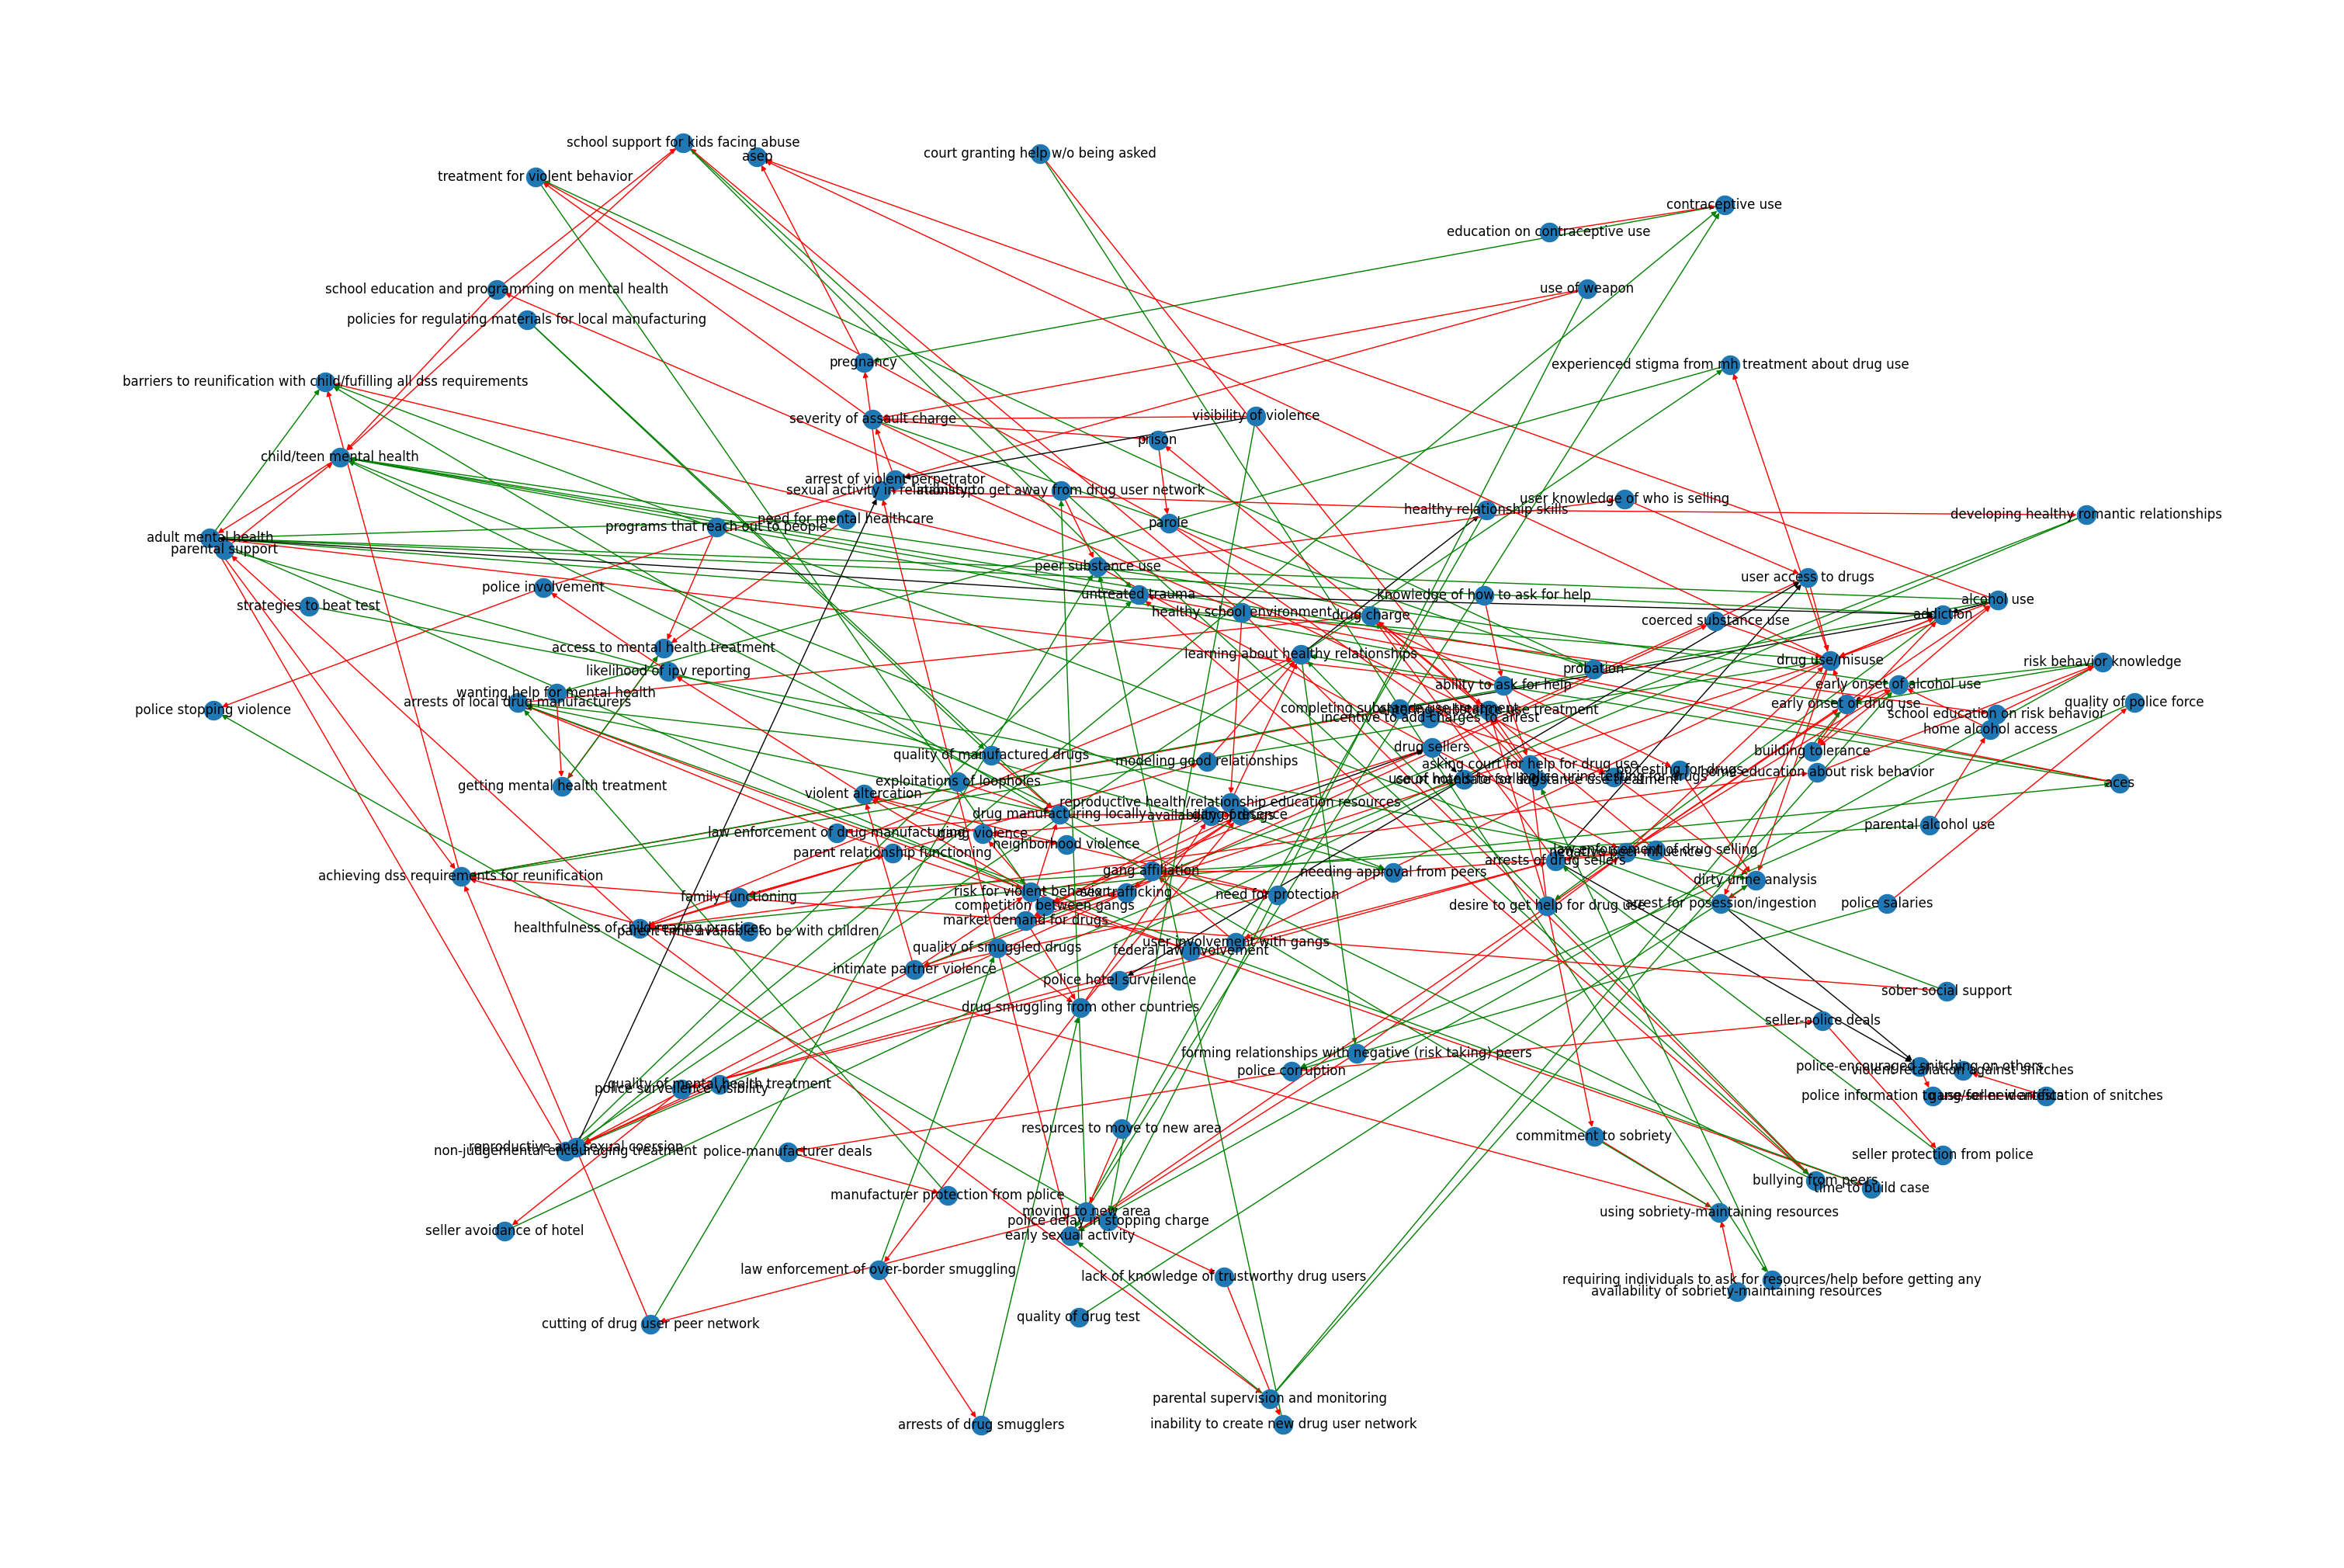

In [102]:
# create a larger plot 
plt.figure(figsize=(30, 20))
pos = nx.spring_layout(G, k=0.15, iterations=50)

# get edge attributes
edge_colors = [G[u][v]['weight'] for u,v in G.edges()]

# draw graph with colored edges
nx.draw(G, pos, with_labels=True, edge_color=[
    'r' if weight == 1 else 'g' if weight == -1 else 'k'
    for weight in edge_colors
])

plt.draw()



## get one pol_mx using the get_theme_cld function

In [83]:
my_data_RC['DSS23.json']

[{1: 'accuracy of assessment',
  2: 'aces',
  3: 'aep',
  4: 'alc norms',
  5: 'alcohol misuse',
  6: 'attourney buy-in',
  7: 'attourney perception',
  8: 'attourney skill',
  9: 'behavioral change',
  10: 'build social supports',
  11: 'case load',
  12: 'caseworker relationship',
  13: 'child removal from home',
  14: 'child welfare intervenes',
  15: 'child witness ipv',
  16: 'childhood home functioning',
  17: 'client buy-in',
  18: 'closed case',
  19: 'court mandate',
  20: 'cultural mistrust',
  21: 'drug use',
  22: 'dss assessment process',
  23: 'dss case management',
  24: 'dss custody',
  25: 'dss referral to resources',
  26: 'dss requirements achieved',
  27: 'ease of assessment',
  28: 'economic support',
  29: 'efficacy of resources',
  30: 'frustration with process',
  31: 'ipv',
  32: 'ipv norms',
  33: 'jail',
  34: 'judge continuance grant',
  35: 'judge perception',
  36: 'knowledge of resources',
  37: 'legal housing',
  38: 'mental health needs',
  39: 'mental 

In [106]:
dict_vars, df = parse_cld.get_dataframe(my_data_RC['drug justice model clean.json'])

df

,from,to,polarity_type,links
0,64,6,-1,1
1,64,54,-1,1
2,64,71,-1,1
3,64,44,1,1
4,64,87,3,1
5,64,53,1,1
6,64,65,-1,1
7,64,109,-1,1
8,6,64,-1,1
9,6,90,1,1


In [107]:
merge_df, theme_dict = parse_cld.get_theme_cld(my_data_RC['DSS23.json'], df_aggregate_names)



adj_mx = parse_cld.get_aggregate_adjacency_mx(merge_df, theme_dict)
pol_nx = parse_cld.get_aggregate_polarity_mx(merge_df, theme_dict)

merge_df



,from,to,polarity_type,links
0,1,23,3,1
1,1,29,3,1
2,2,16,3,1
3,2,38,3,1
4,4,54,3,1
5,9,26,3,1
6,9,43,3,1
7,9,54,3,1
8,9,56,3,1
9,10,9,3,1


In [29]:
# change theme_dict keys to int 
theme_dict

{1: 'accountablility',
 2: 'alcohol exposed pregnancy',
 3: 'alcohol use/misuse',
 19: 'individual protective coping skills',
 5: 'emotional distress',
 6: 'dire situtations',
 7: 'drugs',
 8: 'likelihood of child removal from home',
 9: 'family functioning',
 10: 'healing',
 12: 'intimate partner violence',
 13: 'jail/incarceration',
 14: 'mental health',
 15: 'relationship functioning',
 16: 'passages (re-entry facility)',
 17: 'overall resource quality',
 18: 'supportive people'}

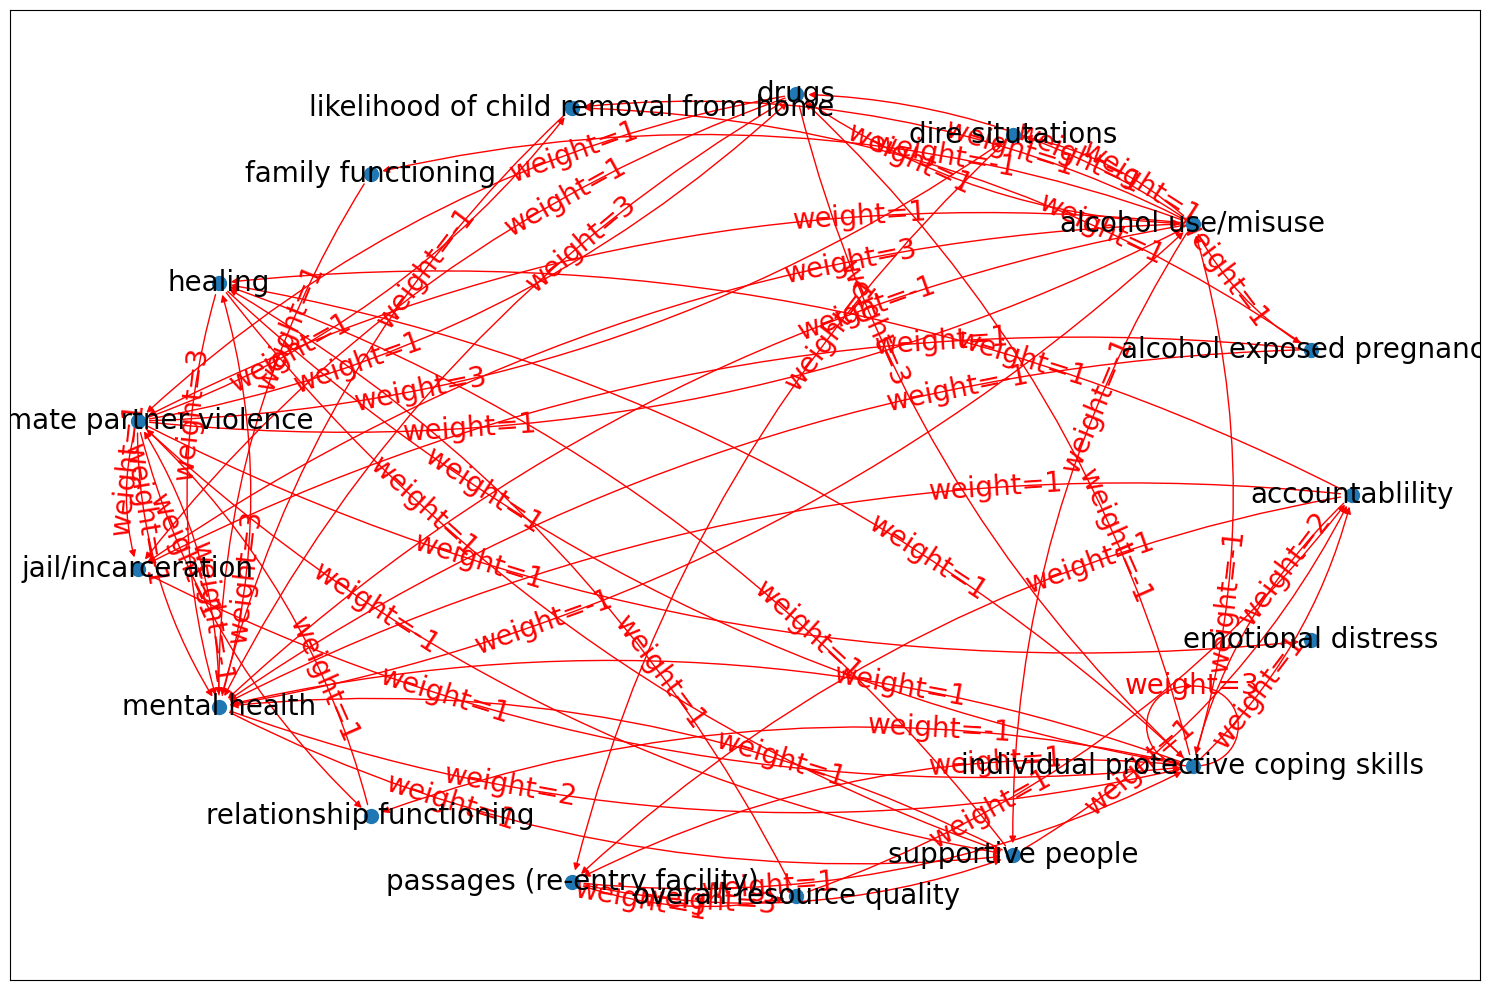

In [30]:
df_subset = merge_df[['from', 'to', 'polarity_type']]
# Change the column name polarity type of weight 
df_subset = df_subset.rename(columns={'polarity_type': 'weight'})

d = parse_cld.get_dict_of_dicts(df_subset)
# print(d)
G_test = nx.MultiDiGraph(d)
# print(dict_var)
cld_nx.draw_labeled_multigraph(G_test, "weight", theme_dict)

In [31]:
adj_mx

to,accountablility,alcohol exposed pregnancy,alcohol use/misuse,emotional distress,dire situtations,drugs,likelihood of child removal from home,family functioning,healing,intimate partner violence,jail/incarceration,mental health,relationship functioning,passages (re-entry facility),overall resource quality,supportive people,individual protective coping skills
from,,,,,,,,,,,,,,,,,
accountablility,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,2
alcohol exposed pregnancy,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0
alcohol use/misuse,0,1,0,0,1,1,1,1,0,1,1,1,0,0,0,1,0
emotional distress,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
dire situtations,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
drugs,0,0,1,0,0,0,0,0,0,1,1,1,0,0,0,0,1
likelihood of child removal from home,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
family functioning,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
healing,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1


In [ ]:
pol_nx.shape

(21, 21)

In [22]:
# pol_nx
G= nx.from_pandas_adjacency(pol_nx, create_using=nx.DiGraph)
# create a larger plot 
plt.figure(figsize=(15,10))
nx.draw(G,with_labels = True)
plt.draw()

NetworkXError: Adjacency matrix not square: nx,ny=(21, 31)

## Get an aggregated CLD for one single CLD 

In [78]:
dict_vars, df = parse_cld.get_dataframe(my_data_RC['DV justice model clean.json'])

print(df.head(3))

for key, value in list(dict_vars.items())[:3]:
    print(f"{key}: {value}")


   from  to  polarity_type  links
0    13  45              1      1
1    13   9              1      1
2    13  40             -1      1
1: \credibility\ of incident
2: ability for victims to recieve housing resources
3: ability to sustain self/kids


Take "Rapid City Update Themes" Excel Sheet "Clean" column B for Aggregated Variable Name and column E for orignial Variable name

In [79]:
# create a dataframe for the single cld var name and the theme 
vars_cld = pd.DataFrame.from_dict(dict_vars, orient='index').reset_index()
# rename columns 
vars_cld.columns = ['vensim_var_no','var_name']
# turn all the variable names to lowercap 
vars_cld['var_name'] = vars_cld['var_name'].str.lower()
# delete the "" sign 
vars_cld['var_name'] = vars_cld['var_name'].str.replace('"', '')
vars_cld.head(3)

,vensim_var_no,var_name
0,1,\credibility\ of incident
1,2,ability for victims to recieve housing resources
2,3,ability to sustain self/kids


In [80]:
# merge the two dataframes and find the theme name for the cld 
df_aggregate_merge = pd.merge(df_aggregate_names, vars_cld, left_on='variable', right_on='var_name', how='right')
df_aggregate_merge.head(5)

,theme,variable,vensim_var_no,var_name
0,NaN,NaN,1,\credibility\ of incident
1,NaN,NaN,2,ability for victims to recieve housing resources
2,NaN,NaN,3,ability to sustain self/kids
3,NaN,NaN,4,adjustment self sufficiency skills
4,likelihood of ending ipv relationship,adjustment to life reorganization without partner,5,adjustment to life reorganization without partner


In [81]:
# merging the cld. Count the duplicate themes. 

df_aggregate_merge['vensim_var_no'] = df_aggregate_merge['vensim_var_no'].astype(int)
# create a new variable number for the theme 

list_of_duplicate_themes = parse_cld.get_duplicate_theme_no(df_aggregate_merge)
print(list_of_duplicate_themes)


['family behaviors and norms around ipv and violence', 'deterrents from ipv reporting', 'perceived credibilty of ipv report', 'ipv', 'effectiveness/quality of policing & justice system', 'severity of incident', 'likelihood of ending ipv relationship', 'reproductive health/relationship education resources', 'level of basic needs unmet ', 'reentry resource quality', 'dependence on others to meet needs', 'likelihood of ipv charge', 'accessability of victims resources', 'cultural mistrust of institutions and institutionally provided resources ', 'individual/family self sustainment']


In [82]:
# create a dictionary where the keys is the orignial var_no and the new var_no is the theme_no

theme_no_dict = {}
for i, val in enumerate(list_of_duplicate_themes):
    theme_no_dict[val] = max(df_aggregate_merge['vensim_var_no']) + i + 1

df_aggregate_merge['theme_no'] = df_aggregate_merge['theme'].map(theme_no_dict)


for i, row in df_aggregate_merge.iterrows():
    if pd.isna(row['theme_no']):
        df_aggregate_merge.at[i, 'theme_no'] = row['vensim_var_no']


df_aggregate_merge['theme_no'] = df_aggregate_merge['theme_no'].astype(int)

df_aggregate_merge.head(5)




,theme,variable,vensim_var_no,var_name,theme_no
0,NaN,NaN,1,\credibility\ of incident,1
1,NaN,NaN,2,ability for victims to recieve housing resources,2
2,NaN,NaN,3,ability to sustain self/kids,3
3,NaN,NaN,4,adjustment self sufficiency skills,4
4,likelihood of ending ipv relationship,adjustment to life reorganization without partner,5,adjustment to life reorganization without partner,90


In [83]:
# create a new dictionary the keys in the vensim vars no, the values is the theme column, if the value is nan, the value is variable 
theme_dict = {}
for index, row in df_aggregate_merge.iterrows():
    if pd.isna(row['theme']):
        theme_dict[row['theme_no']] = row['var_name']
    else:
        theme_dict[row['theme_no']] = row['theme']
        
theme_dict = {int(k): v for k, v in theme_dict.items()}


for key, value in list(theme_dict.items())[:3]:
    print(f"{key}: {value}")


1: \credibility\ of incident
2: ability for victims to recieve housing resources
3: ability to sustain self/kids


In [84]:
theme_org_new_dict = dict(zip(df_aggregate_merge['vensim_var_no'], df_aggregate_merge['theme_no']))

new_df = df.copy()
# change all data in df to int 
new_df = new_df.astype(int)
#swap the from column in df to new number based on theme_no_number_dict
new_df['from'] = new_df['from'].map(theme_org_new_dict)
new_df['to'] = new_df['to'].map(theme_org_new_dict)

merge_df = new_df.groupby(['from', 'to']).sum().reset_index()

merge_df.head(5)


,from,to,polarity_type,links
0,1,86,3,1
1,2,11,1,1
2,3,85,-1,1
3,3,97,-1,1
4,4,90,1,1


In [85]:
pol_mx = parse_cld.get_adjacency_matrix(merge_df)

pol_mx.columns = pol_mx.columns.map(theme_dict)
pol_mx.index = pol_mx.index.map(theme_dict)
pol_mx.head(5)

to,\credibility\ of incident,ability for victims to recieve housing resources,ability to sustain self/kids,adjustment self sufficiency skills,advocate care to victims,advocate case load,overall resource accessibility,alc m,likelihood of arrest,attaining housing resources,...,severity of incident,likelihood of ending ipv relationship,reproductive health/relationship education resources,level of basic needs unmet,reentry resource quality,dependence on others to meet needs,likelihood of ipv charge,accessability of victims resources,cultural mistrust of institutions and institutionally provided resources,individual/family self sustainment
from,,,,,,,,,,,,,,,,,,,,,
\credibility\ of incident,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ability for victims to recieve housing resources,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
ability to sustain self/kids,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
adjustment self sufficiency skills,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
advocate care to victims,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0


In [86]:
# pol_mx.to_csv("aggregate passage_mx.csv")

In [87]:
df_subset = merge_df[['from', 'to', 'polarity_type']]
# Change the column name polarity type of weight 
df_subset = df_subset.rename(columns={'polarity_type': 'weight'})

d = parse_cld.get_dict_of_dicts(df_subset)

g = nx.DiGraph(d)
# relabel the nodes to string names 
g = nx.relabel_nodes(g, theme_dict)

In [88]:
# grab node and edge attributes 

cld_name = 'passage'
g = cld_nx.set_node_attributes(g, unique_theme_names, cld_name =cld_name)
g = cld_nx.set_edge_attributes(g, cld_name =cld_name)


In [89]:
cld_nx.cld_nx_properties(g)
cld_nx.cld_nx_edge_properties(g)
cld_nx.cld_nx_node_properties(g)


Graph data:
-------------
Type: <class 'networkx.classes.digraph.DiGraph'>
Directed: True
Number of nodes: 61
Number of edges: 160
Attributes: {}
Edge data:
-------------
Type: <class 'str'> <class 'str'> <class 'dict'>
Source: \credibility\ of incident
Target: perceived credibilty of ipv report
Attributes: {'weight': 3, 'cld': 'passage'}
Type: <class 'str'> <class 'str'> <class 'dict'>
Source: ability for victims to recieve housing resources
Target: attaining housing resources
Attributes: {'weight': 1, 'cld': 'passage'}
Type: <class 'str'> <class 'str'> <class 'dict'>
Source: ability to sustain self/kids
Target: deterrents from ipv reporting
Attributes: {'weight': -1, 'cld': 'passage'}
Node data:
-------------

Type: <class 'str'> <class 'dict'>
Var Name: \credibility\ of incident
Attributes: {'cld': 'passage', 'level': 'org'}
Degree: 3
Type: <class 'str'> <class 'dict'>
Var Name: ability for victims to recieve housing resources
Attributes: {'cld': 'passage', 'level': 'org'}
Degree: 2

In [90]:
# for source, target, data in g.edges(data=True):
#     print(source, target, data)

In [92]:
# node features

# initialise colour helper 
vals = nx.get_edge_attributes(g, 'weight').values()

# if vals  = 1 color is red, -1 color is blue, 3 is black 
colors = {1: 'red', -1: 'blue', 3: 'black', 2: 'green'} #TODO: check what does 2 means 


# get rgb string for each node
for u, v, data in g.edges(data=True):

    if 'weight' in data:
        if data['weight'] in colors:

            data['color'] = colors[data['weight']]
        else:
            data['color'] = 'green'
    else:
        data['color'] = 'black'

# node feature
for node, data in g.nodes(data=True):
    data['click'] = (
        # f"Node: {data['node_identifier']}"
        "\nNode Features:" +
        f"\nCLD: {data['cld']}" + 
        f"\nLevel: {data['level']}" #+ 
        # f"\nDegree: {data['degree']}"
    )

# edge features
for u, v, data in g.edges(data=True):
  data['click'] = (
        # f"Edge: {g.nodes[u]['node_identifier']} -> {g.nodes[v]['node_identifier']}" +
        f"\nEdge Features:" + 
        f"\nCLD: {data['cld']}" + 
        f"\nPolarity Sign: {data['weight']}"
    )

for node, data in g.nodes(data=True):
    # data['value'] = data['betweenness_centrality'] # node size
    # data['label'] = data['node_identifier'] 
    data['title'] = (
        # f"Node: {data['node_identifier']}"
        "\nNode Features:" +
        f"\nCLD: {data['cld']}" + 
        f"\nLevel: {data['level']}" # + 
        # f"\nDegree: {data['degree']}"
    ) 
    # data['color'] = node_colors.get_rgb_str(data['betweenness_centrality'])


gv.d3(
    g, 
    graph_height=500,
    #    node_size_data_source="betweenness_centrality",
    # use_node_size_normalization=True,
    # node_size_normalization_min=15,
    # node_size_normalization_max=35,
    # show_node_label=False,
    # node_label_data_source='node_identifier',
    
    # edge_size_data_source='feature1',
    # use_edge_size_normalization=True,
    # edge_size_normalization_min=1,
    # edge_size_normalization_max=5,

    # Specify curvature to differentiate between the multiple
    # edges between two nodes.
    edge_curvature=-0.5,
 ) 


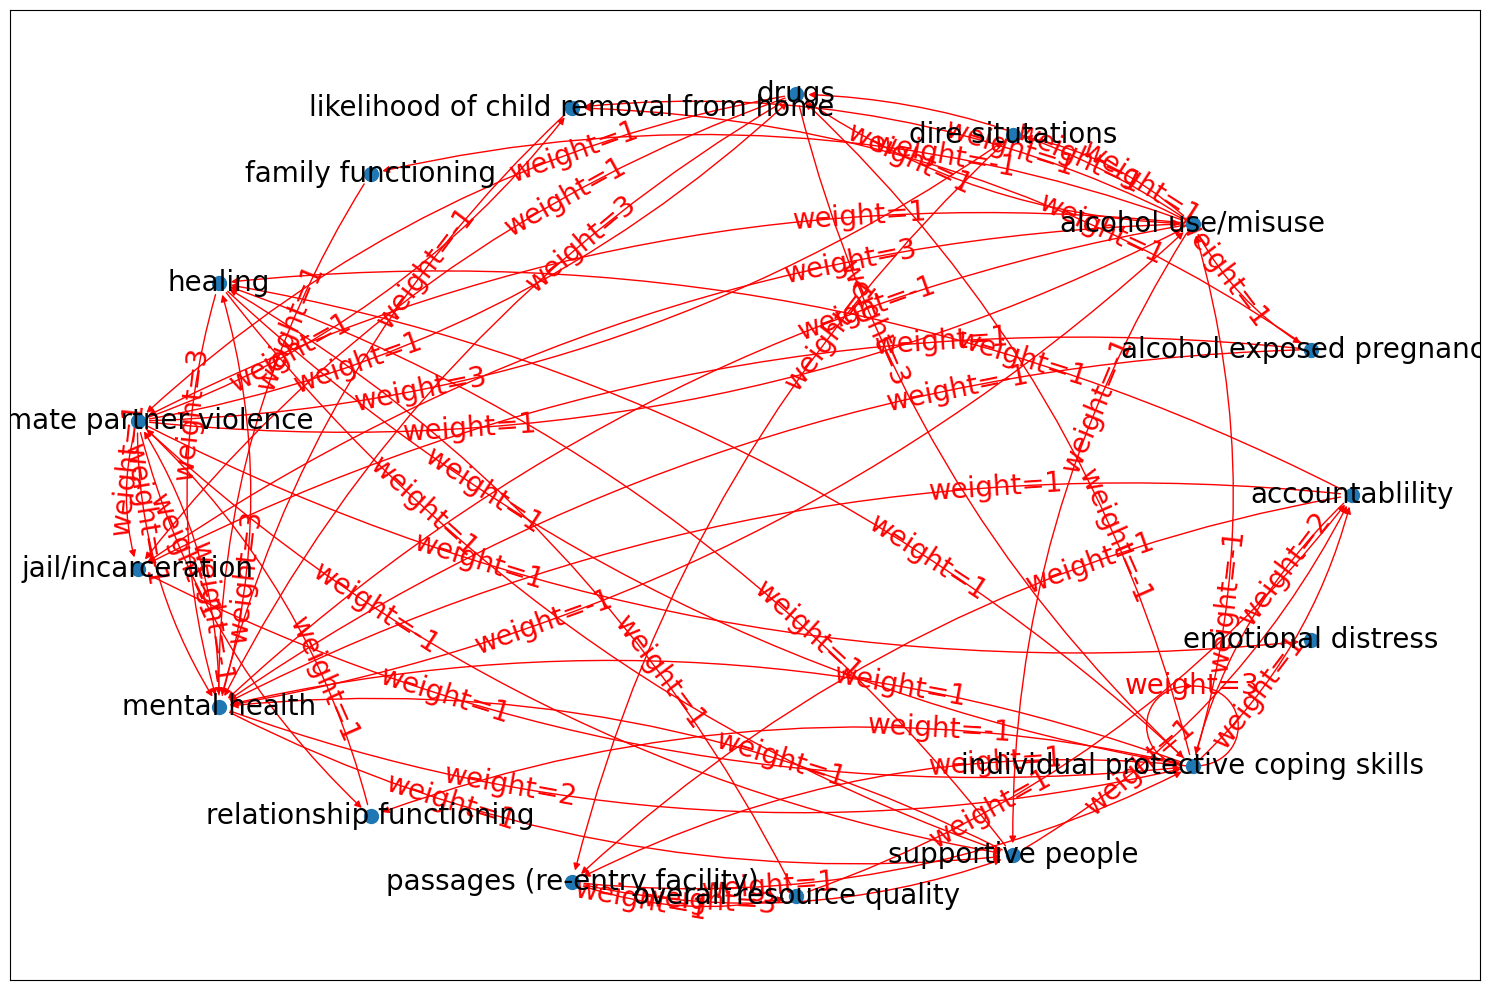

In [ ]:
cld_nx.draw_labeled_multigraph(g, "weight", theme_dict)

In [ ]:
# G= nx.from_pandas_adjacency(pol_mx, create_using=nx.DiGraph)
# # create a larger plot 
# plt.figure(figsize=(15,10))
# nx.draw(G,with_labels = True)
# plt.draw()

## Combining Matrices 

In [ ]:

matrix1 = [[ 1, 1, 1, 0, 1],
        [1, 0, 1, 1, 1],
        [ 1, 0, 0, 0, 0],
        [1, 1, 0, 1, 0],
        [1, 0, 0, 1, 0]]

matrix1 = pd.DataFrame(matrix1, columns=['a', 'b', 'c', 'd', 'e'])
matrix1.index = rows_1
print(matrix1)



matrix2 = [[ 0, 1, 1, 0, 1],
        [1, 0, 1, 1, 1],
        [ 1, 0, 0, 0, 0],
        [1, 1, 0, 1, 0],
        [1, 0, 0, 1, 1]]

matrix2 = pd.DataFrame(matrix2, columns=['z', 'd', 'c', 'b', 'a'])
matrix2.index = rows_2
print("matrix2")
print(matrix2)

   a  b  c  d  e
a  1  1  1  0  1
b  1  0  1  1  1
c  1  0  0  0  0
d  1  1  0  1  0
e  1  0  0  1  0
matrix2
   z  d  c  b  a
z  0  1  1  0  1
d  1  0  1  1  1
c  1  0  0  0  0
b  1  1  0  1  0
a  1  0  0  1  1


In [ ]:
# def combine_non_nan(s1, s2):
#     # print("s1", s1)
#     # print("s2", s2)
#     if pd.isna(s1).all():
#         return s2
#     elif pd.isna(s2).all():
#         return s1
#     else:
#         return s1 + s2



# def get_combine_matrix(matrix1, matrix2): 

#     combined_matrix = matrix1.combine(matrix2, combine_non_nan, overwrite = False)
#     combined_matrix = combined_matrix.fillna(matrix1)
#     combined_matrix = combined_matrix.fillna(matrix2)

#     return combined_matrix 

combined_matrix = parse_cld.get_combine_matrix(matrix1, matrix2)
print(combined_matrix)

     a    b    c    d    e    z
a  2.0  2.0  1.0  0.0  1.0  1.0
b  1.0  1.0  1.0  2.0  1.0  1.0
c  1.0  0.0  0.0  0.0  0.0  1.0
d  2.0  2.0  1.0  1.0  0.0  1.0
e  1.0  0.0  0.0  1.0  0.0  NaN
z  1.0  0.0  1.0  1.0  NaN  0.0


In [ ]:
combined_matrix_ = np.where(combined_matrix == 2, 1, combined_matrix)



(6, 7)


NameError: name 'plt' is not defined

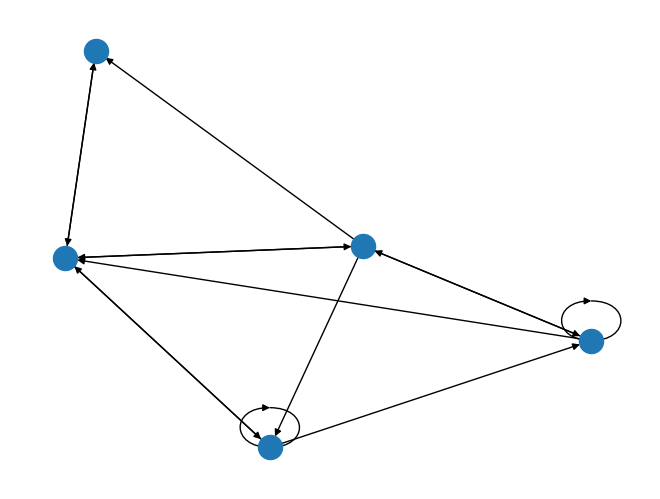

In [ ]:
# import cld_nx
print(combined_matrix.shape)
combined_matrix = combined_matrix.reset_index()
G= nx.from_pandas_adjacency(matrix2, create_using=nx.DiGraph)
nx.draw(G)
plt.draw()